# LAB S04: extracción de información y PLN

Cada sección usa el archivo de `mi_pipeline` que se escribe en su paso de la guía; el cuaderno solo importa y ejecuta. Se trabaja con documentos ficticios y con el texto que leyó el OCR en la sesión anterior; ningún documento se sube a servicios en la nube.

## 0. Dónde están los datos de práctica

In [1]:
# Celda estándar de localización de datos (no se modifica)
import os
from pathlib import Path


def localizar_carpeta(nombre="02_Datos_Practica", max_niveles=6, obligatorio=True):
    """Busca `nombre` en la carpeta actual y en sus carpetas superiores."""
    actual = Path.cwd().resolve()
    for carpeta in [actual, *actual.parents][: max_niveles + 1]:
        candidata = carpeta / nombre
        if candidata.is_dir():
            return candidata
    # Respaldo: carpetas del curso en la unidad del sistema (VM de laboratorio)
    curso = Path(os.environ.get("SystemDrive", "C:") + os.sep) / "curso"
    respaldo = [curso / "paquete" / nombre]
    if nombre == "02_Datos_Practica":
        respaldo.insert(0, curso / "datos")
    for candidata in respaldo:
        if candidata.is_dir():
            return candidata
    if obligatorio:
        raise FileNotFoundError(
            f"No se encuentra la carpeta '{nombre}'. El cuaderno se abre desde su carpeta "
            "dentro del repositorio del curso, sin moverlo de lugar."
        )
    return None


DATOS = localizar_carpeta("02_Datos_Practica")
print("Datos de práctica encontrados:", DATOS.name)
print("Subcarpetas:", sorted(p.name for p in DATOS.iterdir() if p.is_dir()))


Datos de práctica encontrados: datos
Subcarpetas: ['01_Lote_S02', '02_Oficios', '03_Estados_Financieros', '04_Contratos', '05_Polizas', '06_Reclamos', '07_Tarifarios', '08_Vouchers', '09_Formularios', '10_Ground_Truth', '11_Salidas_Precalculadas', '12_Actas', '13_Expedientes', '14_Publico_Real']


## Paso 0: Conexión con `mi_pipeline` y rama de trabajo (C0)

In [2]:
# Conexión de mi_pipeline y de las herramientas del LAB (no se modifica)
%load_ext autoreload
%autoreload 2
import email
import html
import json
import os
import re
import subprocess
import sys
import tempfile
import time
import warnings
from email import policy

import pandas as pd
from IPython.display import HTML, display

os.environ.setdefault("HF_HUB_OFFLINE", "1")   # los modelos ya están en la VM: no se descarga nada
os.environ["TRANSFORMERS_VERBOSITY"] = "error"   # Transformers solo muestra errores, no avisos internos que no cambian el resultado
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # sin barras de carga de los modelos
warnings.filterwarnings("ignore", message="IProgress not found")   # oculta el aviso de la barra de avance, que aquí no hace falta
warnings.filterwarnings("ignore", category=FutureWarning)   # oculta los avisos de cambios futuros de las bibliotecas, que no cambian el resultado
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 50)


def localizar_raiz(max_niveles=6):
    """Carpeta del repositorio clonado que contiene mi_pipeline."""
    if os.environ.get("MI_PIPELINE_RAIZ"):
        return Path(os.environ["MI_PIPELINE_RAIZ"])
    actual = Path.cwd().resolve()
    for carpeta in [actual, *actual.parents][: max_niveles + 1]:
        if (carpeta / "mi_pipeline" / "__init__.py").is_file():
            return carpeta
    clon = Path(os.environ.get("SystemDrive", "C:") + os.sep) / "curso" / "trabajo" / "entorno-extraccion-documental"
    if (clon / "mi_pipeline" / "__init__.py").is_file():
        return clon
    raise FileNotFoundError("No se encuentra la carpeta mi_pipeline: se creó en la sesión anterior.")


RAIZ = localizar_raiz()
sys.path.insert(0, str(RAIZ))
SALIDAS = Path("salidas")
SALIDAS.mkdir(exist_ok=True)
PRECALCULADAS = DATOS / "11_Salidas_Precalculadas"
OCR_GUARDADO = PRECALCULADAS / "ocr_s04"
CONTROLES = []
INICIO = time.perf_counter()


def correr_pruebas():
    """Corre las pruebas de mi_pipeline con pytest, muestra el resumen y dice si todas pasaron."""
    corrida = subprocess.run(
        [sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", str(RAIZ / "mi_pipeline" / "tests")],
        capture_output=True, text=True, cwd=str(RAIZ), timeout=600, encoding="utf-8", errors="replace",
    )
    resumen = [linea for linea in corrida.stdout.strip().splitlines() if " passed" in linea or " failed" in linea or "error" in linea]
    print(re.sub(r" in [\d.]+s.*", "", resumen[-1]) if resumen else corrida.stdout[-500:])
    return corrida.returncode == 0


def leer_correos_con_ocr(receta, psm, enderezar):
    """Cuerpo de cada correo y texto del OCR de su adjunto, leído con `ejecutar` de S03 y los ajustes indicados."""
    from mi_pipeline.pipeline import cargar_configuracion, ejecutar

    cfg = cargar_configuracion()
    cfg["ocr"]["psm"] = psm
    correos = {}
    with tempfile.TemporaryDirectory() as carpeta:
        for eml in sorted((DATOS / "06_Reclamos").glob("REC-*.eml")):
            mensaje = email.message_from_binary_file(eml.open("rb"), policy=policy.default)
            adjunto = next(mensaje.iter_attachments())
            archivo = Path(carpeta) / adjunto.get_filename()
            archivo.write_bytes(adjunto.get_content())
            ocr = ejecutar(archivo, cfg, receta=receta, enderezar=enderezar)["texto"]
            correos[eml.stem] = {"cuerpo": mensaje.get_body(preferencelist=("plain",)).get_content().strip(), "ocr": ocr}
    return correos


def cargar_lote():
    """Los 60 reclamos: asunto, cuerpo, texto del OCR del adjunto (ya guardado), texto completo y respuestas correctas."""
    from mi_pipeline.extraccion.texto import cargar_texto, leer_correo

    lote = []
    for eml in sorted((DATOS / "06_Reclamos").glob("REC-*.eml")):
        correo = leer_correo(eml)
        ocr = cargar_texto(OCR_GUARDADO / "reclamos" / f"{eml.stem}.json")
        correcto = json.loads((DATOS / "10_Ground_Truth" / f"{eml.stem}.json").read_text(encoding="utf-8"))["campos"]
        lote.append({"id": eml.stem, "asunto": correo["asunto"], "cuerpo": correo["cuerpo"], "ocr": ocr,
                     "texto": f"De: {correo['remitente']}\n{correo['cuerpo']}\n{ocr}", "correcto": correcto})
    return lote


COLORES = {"verde": "#c8f0c8", "azul": "#cfe3ff", "naranja": "#ffe0b3", "rojo": "#ffc9c9"}


def resaltar(titulo, texto, marcas, esperados=()):
    """Muestra el texto con cada dato marcado de color. `marcas` es una lista de (cadena, color, etiqueta).
    `esperados` es una lista de (etiqueta, valor correcto): debajo del título se dice si cada valor aparece en el texto."""
    avisos = ""
    for etiqueta, valor in esperados:
        if str(valor) in texto:
            avisos += f'<div style="color:#0a5c0a">✔ {html.escape(etiqueta)} {html.escape(str(valor))}: aparece en el texto (va marcado).</div>'
        else:
            avisos += f'<div style="color:#a40000">✘ {html.escape(etiqueta)} {html.escape(str(valor))}: NO aparece en el texto; el OCR no lo leyó bien, por eso no hay marca.</div>'
    cuerpo = html.escape(texto)
    vistos = set()
    for cadena, color, etiqueta in marcas:
        if not cadena or str(cadena) in vistos:
            continue
        vistos.add(str(cadena))
        dato = html.escape(str(cadena))
        cuerpo = cuerpo.replace(dato, f'<mark style="background:{COLORES[color]};color:#111;padding:0 2px;border-radius:3px">{dato}<sup style="font-size:70%"> {etiqueta}</sup></mark>')
    display(HTML(f'<div style="margin:6px 0"><b>{html.escape(titulo)}</b>{avisos}'
                 f'<pre style="white-space:pre-wrap;font-size:13px;border:1px solid #ccc;padding:8px;background:#fafafa;color:#111">{cuerpo}</pre></div>'))


print("Carpeta del repositorio:", RAIZ.name, "| reclamos:", len(list((DATOS / "06_Reclamos").glob("REC-*.eml"))))


Carpeta del repositorio: entorno-extraccion-documental | reclamos: 60


In [3]:
# ✔ Control C0: la rama de trabajo
rama = subprocess.run(["git", "branch", "--show-current"], cwd=RAIZ, capture_output=True, text=True).stdout.strip()
assert rama == "trabajo-s04", f"C0: la rama actual es '{rama}'; la guía indica crear trabajo-s04 desde trabajo-s03."
CONTROLES.append("C0")
print("✔ C0 superado: rama de trabajo", rama)

✔ C0 superado: rama de trabajo trabajo-s04


ENCABEZADO DEL CORREO
  De: Jorge Fuentes Bravo <jorge.fuentes6@ejemplo.pe>
  Para: reclamos@ejemplo.pe
  Fecha: Thu, 10 Sep 2026 10:04:00 -0500
  Asunto: Reclamo - demora en entrega
  Adjunto: adjunto_REC-0001.jpg


ADJUNTO (la foto o el escaneo que acompaña al correo; es la mitad de arriba):


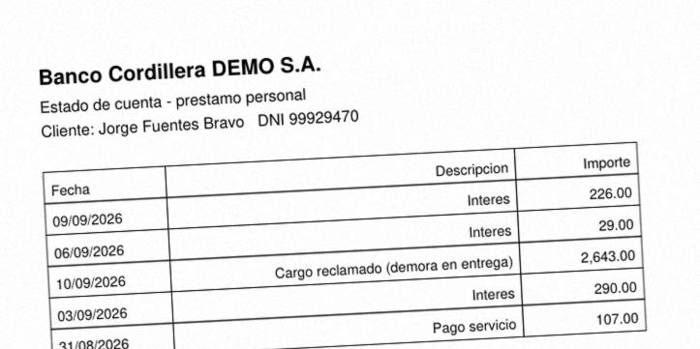

DATOS QUE EL PIPELINE DEBE EXTRAER DE ESTE RECLAMO (la respuesta correcta):
numero_reclamo                  R-2026-139576
fecha                              2026-09-10
nombre                    Jorge Fuentes Bravo
dni                                  99929470
entidad            Banco Cordillera DEMO S.A.
producto                    prestamo personal
motivo                      demora en entrega
monto_reclamado                        2643.0
telefono                          999 000 680
correo              jorge.fuentes6@ejemplo.pe


In [4]:
# Cómo llega un reclamo: el correo (encabezado, cuerpo y adjunto) y los datos que se quieren sacar de él
from io import BytesIO
from PIL import Image

eml = DATOS / "06_Reclamos" / "REC-0001.eml"
mensaje = email.message_from_binary_file(eml.open("rb"), policy=policy.default)
cuerpo_reclamo = mensaje.get_body(preferencelist=("plain",)).get_content().strip()
adjunto = next(mensaje.iter_attachments())
correcto = json.loads((DATOS / "10_Ground_Truth" / "REC-0001.json").read_text(encoding="utf-8"))["campos"]
print("ENCABEZADO DEL CORREO")
for clave, valor in [("De", mensaje["From"]), ("Para", mensaje["To"]), ("Fecha", mensaje["Date"]), ("Asunto", mensaje["Subject"]), ("Adjunto", adjunto.get_filename())]:
    print(f"  {clave}: {valor}")
frase_monto = next(s for s in re.split(r"(?<=[.!?])\s", cuerpo_reclamo) if "soles" in s)
resaltar("CUERPO DEL CORREO (lo que escribe la persona; cada dato que se quiere sacar va marcado)", cuerpo_reclamo,
         [(correcto["nombre"], "azul", "nombre"), (correcto["dni"], "verde", "DNI"), (correcto["entidad"], "naranja", "entidad"),
          (frase_monto, "rojo", "monto en palabras"), (correcto["telefono"], "azul", "teléfono")])
foto = Image.open(BytesIO(adjunto.get_content())).convert("RGB")
foto = foto.crop((0, 0, foto.size[0], int(foto.size[1] * 0.5)))
print("ADJUNTO (la foto o el escaneo que acompaña al correo; es la mitad de arriba):")
display(foto.resize((700, int(700 * foto.size[1] / foto.size[0]))))
print("DATOS QUE EL PIPELINE DEBE EXTRAER DE ESTE RECLAMO (la respuesta correcta):")
print(pd.Series({k: v for k, v in correcto.items() if k not in ("adjunto", "canal", "monto_en_texto")}, name="REC-0001").to_string())

**Cómo leer esta salida**

- **Qué se ve:** Un reclamo completo: el encabezado del correo, el cuerpo con el nombre, el DNI, la entidad, el monto en palabras y el teléfono marcados de color, la imagen del adjunto y la lista de datos correctos que se quieren extraer.
- **Qué significan los números:** El monto aparece escrito en palabras en el cuerpo y como cifras en el adjunto; el DNI y el teléfono tienen formato fijo (ocho cifras que empiezan en 99, y 999 000 seguido de tres cifras).
- **Qué se decide con esto:** Cada reclamo trae los mismos campos, pero escritos de forma distinta. Lo que sigue en el cuaderno enseña a sacarlos con reglas, spaCy y Transformers, y a medir cuántos acierta cada enfoque.

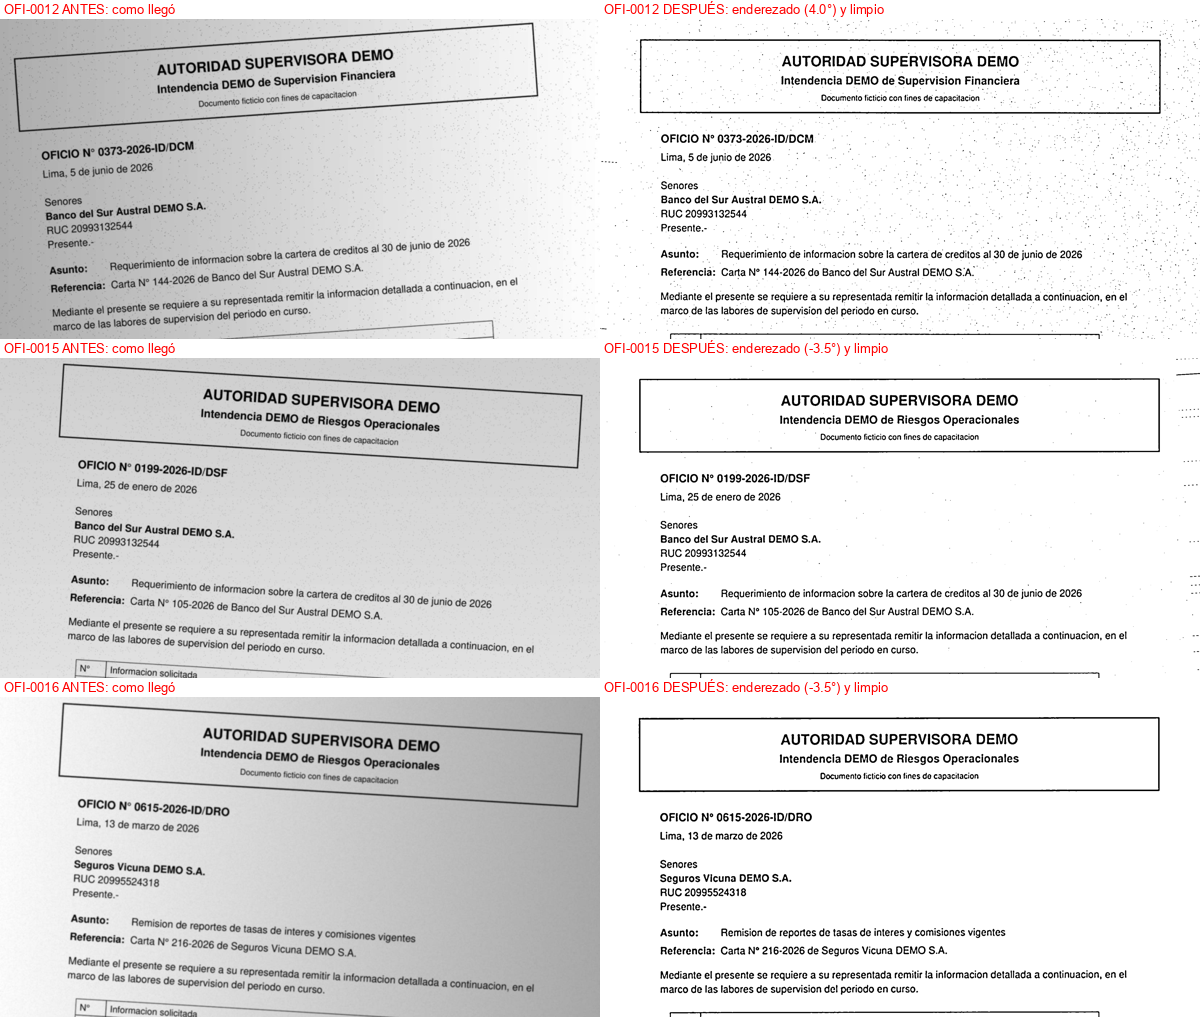

In [5]:
# Puente con S03 (1 de 3): los oficios escaneados como llegaron y como los dejó el preprocesado de S03
from PIL import Image, ImageDraw, ImageFont
from mi_pipeline.ocr.renderizar import pdf_a_imagen
from mi_pipeline.pipeline import cargar_configuracion, ejecutar

cfg_ofi = cargar_configuracion()
try:
    letra = ImageFont.truetype("arial.ttf", 13)      # con tildes
except OSError:
    letra = None
filas_ofi = []
for id_ in ["OFI-0012", "OFI-0015", "OFI-0016"]:
    ruta_pdf = DATOS / "02_Oficios" / f"{id_}.pdf"
    antes = Image.fromarray(pdf_a_imagen(ruta_pdf, 0, 100)).convert("RGB")                 # el escaneo tal como llegó
    lectura = ejecutar(ruta_pdf, cfg_ofi, receta="mediana", enderezar=True)                # lo que hizo S03: enderezar y limpiar
    despues = Image.fromarray(lectura["imagen"]).convert("RGB")
    pareja = []
    for foto, rotulo in [(antes, f"{id_} ANTES: como llegó"), (despues, f"{id_} DESPUÉS: enderezado ({lectura['inclinacion']:.1f}°) y limpio")]:
        foto = foto.crop((0, 0, foto.size[0], int(foto.size[1] * 0.4)))
        foto = foto.resize((600, int(600 * foto.size[1] / foto.size[0])))
        ImageDraw.Draw(foto).rectangle((0, 0, 600, 18), fill="white")
        ImageDraw.Draw(foto).text((4, 2), rotulo, fill="red", font=letra)
        pareja.append(foto)
    filas_ofi.append(pareja)
alto_fila = max(f.size[1] for pareja in filas_ofi for f in pareja)
lamina_antes = Image.new("RGB", (1200, alto_fila * len(filas_ofi)), "white")
for fila, pareja in enumerate(filas_ofi):
    for col, foto in enumerate(pareja):
        lamina_antes.paste(foto, (col * 600, fila * alto_fila))
display(lamina_antes)

**Cómo leer esta salida**

- **Qué se ve:** Tres oficios escaneados en dos columnas: a la izquierda, como llegaron (inclinados, con sombra y ruido); a la derecha, como los dejó S03 tras enderezarlos y limpiarlos. El rótulo rojo dice cuántos grados se corrigió la inclinación.
- **Qué significan los números:** Los grados son la inclinación que S03 midió y corrigió; no hay otros números.
- **Qué se decide con esto:** Es el cambio que S03 ya aplicó. Lo que sigue verifica si el texto leído de esas imágenes salió bien o mal.

Oficios escaneados que S03 leyó, contra su texto correcto (CER: 0 es perfecto; sobre 0,10 hay muchos errores):
         decisión de S03  confianza  errores por carácter (CER)  campos mal leídos (de 3)                       cuáles
oficio                                                                                                                
OFI-0001         aceptar        0.9                        0.06                         1                numero_oficio
OFI-0002         aceptar        0.9                        0.05                         1                numero_oficio
OFI-0003         aceptar        0.9                        0.06                         1                numero_oficio
OFI-0005         aceptar        0.9                        0.05                         1                numero_oficio
OFI-0012         revisar        0.6                        0.34                         3  numero_oficio, ruc, entidad
OFI-0015         aceptar        0.7                     

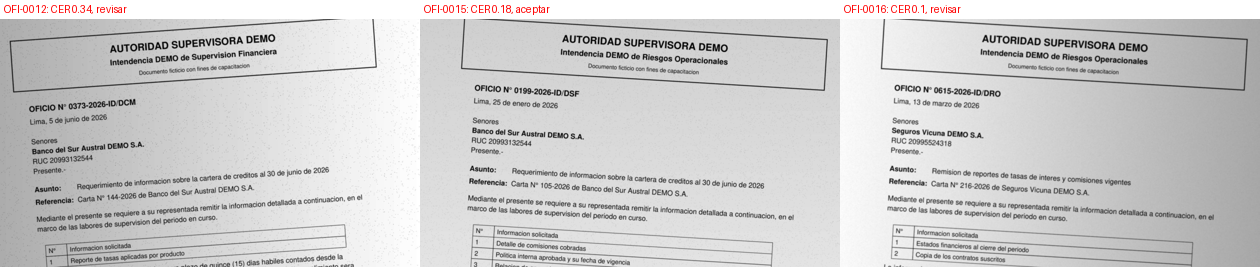

In [6]:
# Puente con S03 (2 de 3): los oficios escaneados que S03 leyó, comparados con el texto correcto de cada uno
from PIL import Image, ImageDraw
from mi_pipeline.calidad.metricas import cer
from mi_pipeline.ocr.renderizar import pdf_a_imagen

filas = []
for archivo in sorted((OCR_GUARDADO / "oficios").glob("OFI-*.json")):
    leido = json.loads(archivo.read_text(encoding="utf-8"))
    correcto = json.loads((DATOS / "10_Ground_Truth" / archivo.name).read_text(encoding="utf-8"))
    campos = {k: str(correcto["campos"][k]) for k in ("numero_oficio", "ruc", "entidad")}
    mal = [k for k, v in campos.items() if v not in leido["texto"]]
    filas.append({"oficio": archivo.stem, "decisión de S03": leido["decision"], "confianza": round(leido["confianza"], 1),
                  "errores por carácter (CER)": round(cer(correcto["texto_completo"], leido["texto"]), 2),
                  "campos mal leídos (de 3)": len(mal), "cuáles": ", ".join(mal) or "ninguno"})
tabla_ofi = pd.DataFrame(filas).set_index("oficio")
print("Oficios escaneados que S03 leyó, contra su texto correcto (CER: 0 es perfecto; sobre 0,10 hay muchos errores):")
print(tabla_ofi.to_string())
peores = tabla_ofi.sort_values("errores por carácter (CER)", ascending=False).index[:3]
miniaturas = []
for id_ in peores:
    pagina = Image.fromarray(pdf_a_imagen(DATOS / "02_Oficios" / f"{id_}.pdf", 0, 100)).convert("RGB")
    pagina = pagina.crop((0, 0, pagina.size[0], int(pagina.size[1] * 0.45)))
    pagina = pagina.resize((420, int(420 * pagina.size[1] / pagina.size[0])))
    ImageDraw.Draw(pagina).rectangle((0, 0, 420, 18), fill="white")
    ImageDraw.Draw(pagina).text((4, 3), f"{id_}: CER {tabla_ofi.loc[id_, 'errores por carácter (CER)']}, {tabla_ofi.loc[id_, 'decisión de S03']}", fill="red")
    miniaturas.append(pagina)
lamina_ofi = Image.new("RGB", (420 * 3, max(m.size[1] for m in miniaturas)), "white")
for k, m in enumerate(miniaturas):
    lamina_ofi.paste(m, (k * 420, 0))
display(lamina_ofi)

**Cómo leer esta salida**

- **Qué se ve:** Una tabla con los oficios escaneados que S03 leyó (decisión, confianza, CER y campos clave mal leídos) y una lámina con el escaneo de los tres peores.
- **Qué significan los números:** El CER es la fracción de caracteres que el OCR leyó mal: 0,05 es un error cada veinte caracteres; sobre 0,10 ya hay errores en datos que importan. «Campos mal leídos» cuenta cuántos de tres campos clave no aparecen tal cual en el texto.
- **Qué se decide con esto:** Un oficio con campos mal leídos no se puede dar por bueno aunque S03 lo haya aceptado: S04 parte de este texto y las reglas heredan el error.

Decisión que S03 tomó con cada uno de los 60 adjuntos:
decisión de S03
aceptar     30
rechazar    28
revisar      2
DNI correcto presente en el texto que leyó S03: 31 de 60
decisión de S03
aceptar     30
rechazar     0
revisar      1
Los 6 adjuntos con menor confianza (imagen tal como la dejó S03): REC-0003, REC-0005, REC-0012, REC-0009, REC-0013, REC-0032


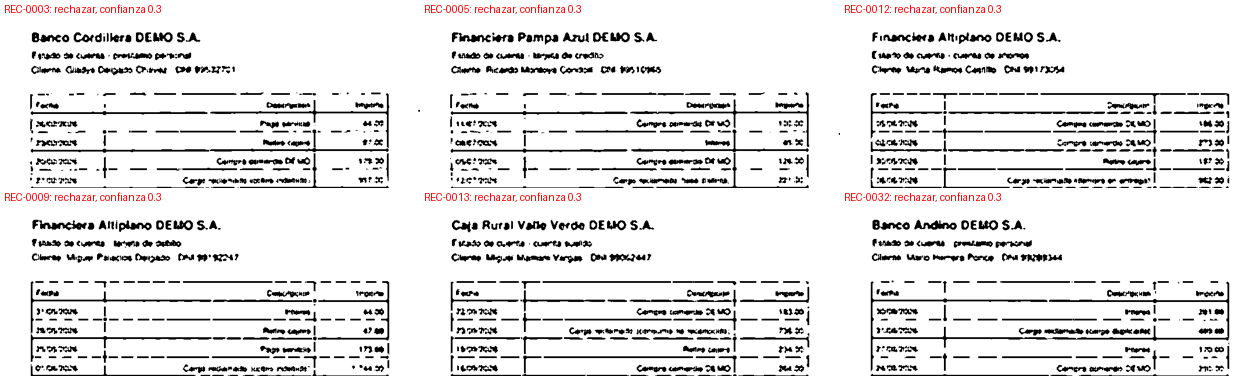

Texto que S04 recibe de REC-0003 (primeras líneas):
Banco Cordillera DEMO S.A,
Fraao de Citan | Cro pc
Cilmena. Ciimbro Cepas Cira CI III!
Vo era] mp]
[oecracos_ A A A
"coa / pu capo no .“n


In [7]:
# Puente con S03 (3 de 3): los 60 adjuntos leídos con el `ejecutar` de S03 y los que S03 no pudo leer bien
from PIL import Image, ImageDraw
from mi_pipeline.pipeline import cargar_configuracion, ejecutar

cfg_s03 = cargar_configuracion()                    # ajustes del YAML de S03
lecturas_s03 = {}
with tempfile.TemporaryDirectory() as carpeta:
    for eml in sorted((DATOS / "06_Reclamos").glob("REC-*.eml")):
        mensaje = email.message_from_binary_file(eml.open("rb"), policy=policy.default)
        adjunto = next(mensaje.iter_attachments())
        archivo = Path(carpeta) / adjunto.get_filename()
        archivo.write_bytes(adjunto.get_content())
        lecturas_s03[eml.stem] = ejecutar(archivo, cfg_s03)
dni_correcto = {i: json.loads((DATOS / "10_Ground_Truth" / f"{i}.json").read_text(encoding="utf-8"))["campos"]["dni"] for i in lecturas_s03}
tabla_s03 = pd.DataFrame({"decisión de S03": [l["decision"] for l in lecturas_s03.values()],
                          "confianza": [round(l["confianza"], 1) for l in lecturas_s03.values()],
                          "DNI bien leído": [dni_correcto[i] in l["texto"] for i, l in lecturas_s03.items()]}, index=list(lecturas_s03))
print("Decisión que S03 tomó con cada uno de los 60 adjuntos:")
print(tabla_s03["decisión de S03"].value_counts().to_string())
print("DNI correcto presente en el texto que leyó S03:", int(tabla_s03["DNI bien leído"].sum()), "de 60")
print(tabla_s03.groupby("decisión de S03")["DNI bien leído"].sum().rename("DNI bien leído").to_string())
con_problemas = tabla_s03[tabla_s03["decisión de S03"] != "aceptar"].sort_values("confianza").index[:6]
print("Los 6 adjuntos con menor confianza (imagen tal como la dejó S03):", ", ".join(con_problemas))
miniaturas = []
for id_ in con_problemas:
    foto = Image.fromarray(lecturas_s03[id_]["imagen"]).convert("RGB")
    foto = foto.crop((0, 0, foto.size[0], int(foto.size[1] * 0.45)))     # solo la parte de arriba, donde está el texto
    foto = foto.resize((420, int(420 * foto.size[1] / foto.size[0])))
    ImageDraw.Draw(foto).rectangle((0, 0, 420, 18), fill="white")
    ImageDraw.Draw(foto).text((4, 3), f"{id_}: {lecturas_s03[id_]['decision']}, confianza {lecturas_s03[id_]['confianza']:.1f}", fill="red")
    miniaturas.append(foto)
alto = max(m.size[1] for m in miniaturas)
lamina = Image.new("RGB", (420 * 3, alto * 2), "white")
for k, m in enumerate(miniaturas):
    lamina.paste(m, ((k % 3) * 420, (k // 3) * alto))
display(lamina)
mejor = con_problemas[0]
print(f"Texto que S04 recibe de {mejor} (primeras líneas):")
print(chr(10).join(lecturas_s03[mejor]["texto"].splitlines()[:6]))

**Cómo leer esta salida**

- **Qué se ve:** Un conteo de las decisiones de S03 sobre los 60 adjuntos, cuántos conservaron el DNI correcto en el texto, una lámina con las 6 imágenes que peor se leyeron (cada una con su decisión y su confianza) y las primeras líneas del texto de la peor.
- **Qué significan los números:** Cada número del conteo es una cantidad de adjuntos, de 60; «DNI bien leído» cuenta los que traen el DNI correcto en el texto, y se desglosa por la decisión que tomó S03. La confianza va de 0 a 100: mide qué tan seguro quedó el OCR. Los rótulos rojos de la lámina son la decisión y la confianza de S03 para ese adjunto.
- **Qué se decide con esto:** S04 trabaja sobre ese texto: si S03 lo dejó con errores, las reglas de hoy los heredan.

## Reto: extraer DNI, fecha y monto de 60 correos con `re.findall`

In [8]:
# Reto: DNI, fecha y monto de los 60 correos con re.findall, sobre el texto del adjunto que lee el OCR de S03
ajustes_s03 = leer_correos_con_ocr(receta="mediana", psm=6, enderezar=True)      # valores del YAML de S03 (hechos para oficios)
ajustes_adjunto = leer_correos_con_ocr(receta="crudo", psm=3, enderezar=False)   # valores que sirven para este adjunto


def contar(correos, campo, patron):
    """Cuántos de los 60 correos traen el patrón en el campo indicado (cuerpo u ocr)."""
    return sum(bool(re.findall(patron, c[campo])) for c in correos.values())


reto = pd.DataFrame({"OCR con ajustes de S03": [contar(ajustes_s03, "ocr", r"99\d{6}")],
                     "OCR con ajustes del adjunto": [contar(ajustes_adjunto, "ocr", r"99\d{6}")]}, index=["DNI leído en el adjunto"])
reto.loc["fecha completa en el adjunto"] = [contar(c, "ocr", r"\d{2}/\d{2}/\d{4}") for c in (ajustes_s03, ajustes_adjunto)]
reto.loc["monto con S/ en el cuerpo"] = [contar(ajustes_adjunto, "cuerpo", r"S/\s*[\d,]+")] * 2
print(reto)

                              OCR con ajustes de S03  OCR con ajustes del adjunto
DNI leído en el adjunto                           31                           59
fecha completa en el adjunto                      18                           60
monto con S/ en el cuerpo                         27                           27


**Cómo leer esta salida**

- **Qué se ve:** Una tabla con tres campos (DNI, fecha completa y monto con «S/») y, por columna, cuántos de los 60 correos se leyeron bien con el OCR de S03 y con los ajustes propios del adjunto.
- **Qué significan los números:** Cada número es una cantidad de correos, de 60, donde la expresión regular halló el dato correcto. Con el OCR de S03 el DNI sale en cerca de la mitad de los correos y la fecha en menos de un tercio; con los ajustes, en 59 y 60 correos. El monto con «S/» es igual en ambas (27) porque está en el cuerpo del correo y no en el adjunto.
- **Qué se decide con esto:** La regla es la misma y cambia el texto que recibe: si el OCR lee mal, la regla falla aunque esté bien escrita.

In [9]:
# Ver el reto: el mismo adjunto leído con los ajustes de S03 y con los ajustes del adjunto, con cada dato hallado marcado
id_ver = next(i for i in ajustes_s03 if not re.findall(r"99\d{6}", ajustes_s03[i]["ocr"]) and re.findall(r"99\d{6}", ajustes_adjunto[i]["ocr"]))
correcto_ver = json.loads((DATOS / "10_Ground_Truth" / f"{id_ver}.json").read_text(encoding="utf-8"))["campos"]
print(f"Correo {id_ver}: DNI correcto {correcto_ver['dni']}, fecha correcta {correcto_ver['fecha']}")
for titulo, lectura in [("Con los ajustes de S03 (receta mediana, psm 6)", ajustes_s03), ("Con los ajustes del adjunto (receta cruda, psm 3)", ajustes_adjunto)]:
    texto = lectura[id_ver]["ocr"]
    marcas = [(m, "verde", "DNI") for m in re.findall(r"99\d{6}", texto)] + [(m, "azul", "fecha") for m in re.findall(r"\d{2}/\d{2}/\d{4}", texto)]
    resaltar(titulo, texto[:700], marcas, esperados=[("DNI correcto", correcto_ver["dni"])])

Correo REC-0001: DNI correcto 99929470, fecha correcta 2026-09-10


**Cómo leer esta salida**

- **Qué se ve:** El texto del adjunto de un correo, dos veces: con los ajustes de S03 y con los ajustes propios del adjunto. Lo marcado en verde es el DNI que halló la regla y lo marcado en azul, la fecha.
- **Qué significan los números:** Cada recuadro dice, en verde o en rojo, si el DNI correcto aparece en el texto. Con los ajustes de S03 el texto sale ilegible y el DNI no aparece: no hay marca porque no hay dato que leer. Con los del adjunto el DNI aparece marcado.
- **Qué se decide con esto:** Si falta un dato, primero se mira el texto que recibió la regla y solo después se cambia la regla.

In [10]:
# Causas de las fallas: el participante escribe al menos dos, entre comillas y separadas por coma
causas = []
if len(causas) >= 2:
    print(f"✔ Reto superado: anotó {len(causas)} causas ->", "; ".join(causas))
else:
    print("✘ Falta anotar al menos dos causas en la lista `causas` y volver a correr esta celda")

✘ Falta anotar al menos dos causas en la lista `causas` y volver a correr esta celda


## Paso 1: `extraccion/texto.py` (E1, C1 y C2)

In [11]:
# E1: el texto de 5 correos y de sus adjuntos, y su análisis con spaCy (C1)
from mi_pipeline.extraccion.texto import analizar, cargar_texto, formas_base

IDS = ["REC-0001", "REC-0002", "REC-0003", "REC-0004", "REC-0005"]
for id_ in IDS:
    cuerpo = cargar_texto(DATOS / "06_Reclamos" / f"{id_}.eml")
    ocr_json = OCR_GUARDADO / "reclamos" / f"{id_}.json"
    correcto = json.loads((DATOS / "10_Ground_Truth" / f"{id_}.json").read_text(encoding="utf-8"))["texto_completo"]
    # ✔ Control C1
    assert correcto.startswith(cuerpo), f"C1: el cuerpo de {id_} no coincide con el texto correcto."
    assert cargar_texto(ocr_json) == json.loads(ocr_json.read_text(encoding="utf-8"))["texto"].strip(), f"C1: el texto de {id_} no coincide con el del OCR."
CONTROLES.append("C1")
doc = analizar(cargar_texto(DATOS / "06_Reclamos" / "REC-0001.eml"))
print(pd.DataFrame([{"token": t.text, "forma base": t.lemma_, "clase": t.pos_} for t in doc][:12]).T)
print("Entidades que marca spaCy:", [(e.text, e.label_) for e in doc.ents])
print(f"✔ C1 superado: el texto cargado de {len(IDS)} correos y sus adjuntos coincide con el correcto y con el del OCR")

                0      1    2      3        4      5      6      7         8      9    10     11
token       Buenas      ,  soy  Jorge  Fuentes  Bravo      ,    DNI  99929470      .   En  Banco
forma base  Buenas      ,  ser  Jorge  Fuentes  Bravo      ,    DNI  99929470      .   en  Banco
clase        PROPN  PUNCT  AUX  PROPN    PROPN  PROPN  PUNCT  PROPN       NUM  PUNCT  ADP  PROPN
Entidades que marca spaCy: [('Jorge Fuentes Bravo', 'PER'), ('Banco Cordillera DEMO S.A.', 'LOC'), ('Ya fui a la agencia', 'MISC'), ('Mi cel', 'MISC')]
✔ C1 superado: el texto cargado de 5 correos y sus adjuntos coincide con el correcto y con el del OCR


**Cómo leer esta salida**

- **Qué se ve:** Una tabla con las palabras de un correo (`token`), su forma base y su clase gramatical, y las entidades que marca spaCy.
- **Qué significan los números:** `token` es cada palabra o signo; `forma base` es la palabra sin conjugación ni plural (`soy` pasa a `ser`); `clase` es PROPN (nombre propio), NUM (número), ADP (preposición) o PUNCT (signo). Cada entidad trae su tipo: PER (persona), LOC (lugar) o MISC (otros).
- **Qué se decide con esto:** spaCy ya separa y etiqueta el texto, pero sus entidades no son fiables: marca «Banco Cordillera DEMO S.A.» como lugar y «Ya fui a la agencia» como entidad. Por eso se agregan reglas propias.

In [12]:
# Ver E1: las entidades que marca spaCy sobre el cuerpo de un correo y sobre el texto que leyó el OCR de un adjunto
from spacy import displacy

for titulo, ruta in [("Cuerpo del correo REC-0001", DATOS / "06_Reclamos" / "REC-0001.eml"),
                     ("Texto que leyó el OCR del adjunto de REC-0005", OCR_GUARDADO / "reclamos" / "REC-0005.json")]:
    print(titulo)
    displacy.render(analizar(cargar_texto(ruta)), style="ent", jupyter=True)

Cuerpo del correo REC-0001


Texto que leyó el OCR del adjunto de REC-0005


**Cómo leer esta salida**

- **Qué se ve:** El texto de dos documentos con cada entidad que spaCy reconoce subrayada y con su etiqueta: PER es persona, LOC es lugar y MISC es otro tipo.
- **Qué significan los números:** No hay números: cada subrayado es una decisión del modelo.
- **Qué se decide con esto:** Se compara con lo que se lee a simple vista. Donde el modelo se equivoca, hace falta una regla propia.

In [13]:
# E1: formas base (lemas), control C2
print("Formas base:", formas_base("Los cobros indebidos del banco"))
# ✔ Control C2
assert formas_base("cobro")[0] == formas_base("cobros")[0], "C2: «cobro» y «cobros» deben compartir forma base."
CONTROLES.append("C2")
print("✔ C2 superado: «cobro» y «cobros» comparten la forma base", formas_base("cobros")[0])
print("Un error del OCR se hereda:", [t.text for t in analizar(cargar_texto(OCR_GUARDADO / "reclamos" / "REC-0005.json"))][:14])

Formas base: ['el', 'cobro', 'indebido', 'del', 'banco']
✔ C2 superado: «cobro» y «cobros» comparten la forma base cobro
Un error del OCR se hereda: ['Financiera', 'Pampa', 'Azul', 'DEMO', 'S.A.', '\n', 'Estado', 'de', 'cuenta', '-', 'tarjeta', 'de', 'credito', '\n']


**Cómo leer esta salida**

- **Qué se ve:** Las formas base de una frase, una verificación y las palabras que spaCy ve en el texto que leyó el OCR de un adjunto.
- **Qué significan los números:** «cobro» y «cobros» comparten la forma base `cobro`, así que contar formas base junta las variantes de una misma palabra.
- **Qué se decide con esto:** spaCy trabaja sobre el texto que recibe, esté bien o mal leído: la calidad del OCR de S03 limita todo lo que sigue.

## Paso 2: `extraccion/reglas.py` (E2, C3)

In [14]:
# E2: reglas sobre el texto de los 60 reclamos (remitente, cuerpo y OCR del adjunto), control C3
from mi_pipeline.extraccion.reglas import extraer_dni, extraer_fecha

lote = cargar_lote()
pred_dni = [extraer_dni(r["texto"]) for r in lote]
aciertos = sum(p == r["correcto"]["dni"] for p, r in zip(pred_dni, lote))
precision = aciertos / sum(p is not None for p in pred_dni)
recall = aciertos / len(lote)
f1_dni = 2 * precision * recall / (precision + recall)
print(f"DNI: {aciertos} de {len(lote)} correctos, precisión {precision:.2f}, recall {recall:.2f}, F1 {f1_dni:.2f}")
print("Fecha completa correcta en", sum(extraer_fecha(r["texto"]) == r["correcto"]["fecha"] for r in lote), "de", len(lote), "correos")
# ✔ Control C3
assert f1_dni == 1.0, "C3: el F1 del DNI debe ser 1,00."
CONTROLES.append("C3")
print("✔ C3 superado: DNI con F1 =", round(f1_dni, 2))

DNI: 60 de 60 correctos, precisión 1.00, recall 1.00, F1 1.00
Fecha completa correcta en 59 de 60 correos
✔ C3 superado: DNI con F1 = 1.0


**Cómo leer esta salida**

- **Qué se ve:** El resultado de la regla del DNI y de la fecha sobre los 60 correos.
- **Qué significan los números:** Precisión es la proporción de DNI hallados que son correctos; recall, la de DNI existentes que se hallaron; F1 las resume. 60 de 60 correctos da F1 1,00. La fecha completa sale correcta en 59 de 60 correos.
- **Qué se decide con esto:** Una regla bien escrita sobre un texto bien leído da F1 1,00; el correo con la fecha incorrecta se revisa para ver si falló la regla o el OCR.

In [15]:
# Ver E2: qué dato halló cada regla en el texto y dónde falla
malos = [r for r in lote if extraer_fecha(r["texto"]) != r["correcto"]["fecha"]]
como_en_el_texto = lambda iso: f"{iso[8:]}/{iso[5:7]}/{iso[:4]}"     # 2026-05-29 se escribe 29/05/2026 en el documento
for r in [lote[0]] + malos[:1]:
    hallada = extraer_fecha(r["texto"])
    marcas = [(extraer_dni(r["texto"]), "verde", "DNI"), (como_en_el_texto(hallada), "azul", "fecha hallada"), (como_en_el_texto(r["correcto"]["fecha"]), "naranja", "fecha correcta")]
    resaltar(f"{r['id']}: DNI {extraer_dni(r['texto'])}; fecha hallada {hallada}; fecha correcta {r['correcto']['fecha']}", r["texto"], marcas, esperados=[("DNI correcto", r["correcto"]["dni"])])

**Cómo leer esta salida**

- **Qué se ve:** El texto de dos correos con el DNI marcado en verde, la fecha que halló la regla en azul y la fecha correcta en naranja.
- **Qué significan los números:** La primera línea de cada recuadro dice el DNI, la fecha hallada y la correcta. Si coinciden, la regla acertó.
- **Qué se decide con esto:** Cuando las dos fechas difieren, se revisa el texto: el error viene del OCR, que cambió una cifra (un año leído como 2028), y no de la expresión regular.

In [16]:
# E2: RUC con módulo 11 y número de oficio en los oficios escaneados que leyó S03
from mi_pipeline.extraccion.reglas import extraer_numero_oficio, extraer_ruc

filas = []
for ruta in sorted((OCR_GUARDADO / "oficios").glob("OFI-*.json")):
    texto = cargar_texto(ruta)
    campos = json.loads((DATOS / "10_Ground_Truth" / f"{ruta.stem}.json").read_text(encoding="utf-8"))["campos"]
    ruc, numero = extraer_ruc(texto), extraer_numero_oficio(texto)
    ruc_malo = campos["ruc"][:-1] + str((int(campos["ruc"][-1]) + 1) % 10)
    filas.append({"oficio": ruta.stem, "RUC": ruc, "RUC correcto": ruc == campos["ruc"], "con un dígito cambiado": extraer_ruc(texto.replace(campos["ruc"], ruc_malo)),
                  "número": numero, "número correcto": numero == campos["numero_oficio"]})
tabla_oficios = pd.DataFrame(filas).set_index("oficio")
print(tabla_oficios)
assert tabla_oficios["con un dígito cambiado"].isna().all(), "Un RUC con el dígito verificador cambiado no debe aceptarse."

                  RUC  RUC correcto con un dígito cambiado            número  número correcto
oficio                                                                                       
OFI-0001  20992371634          True                   None  0230-2026-ID/DSF             True
OFI-0002  20995524318          True                   None  0955-2026-ID/DSF             True
OFI-0003  20997531206          True                   None  0522-2026-ID/DCM             True
OFI-0005  20996256821          True                   None  0796-2026-ID/DSF             True
OFI-0012          NaN         False                   None  0373-2026-ID/DCM             True
OFI-0015  20993132544          True                   None  0199-2026-ID/DSF             True
OFI-0016  20995524318          True                   None  0615-2026-ID/DRO             True


**Cómo leer esta salida**

- **Qué se ve:** Una fila por oficio escaneado con el RUC hallado, si coincide con el correcto, el resultado de repetir la búsqueda con un dígito cambiado, y el número de oficio con su comprobación.
- **Qué significan los números:** La columna «con un dígito cambiado» queda vacía (`None`) en todas las filas, y eso es lo esperado: la regla rechaza un RUC cuyo dígito verificador no cuadra. En OFI-0012 el RUC sale vacío (`NaN`) y la columna «RUC correcto» da `False`: la regla no halló un RUC válido en lo que leyó el OCR.
- **Qué se decide con esto:** Un dato con dígito verificador se valida, no solo se copia: un RUC mal leído no pasa. Un oficio sin RUC válido se revisa a mano.

In [17]:
# E2: EntityRuler de spaCy: patrones propios (DNI, teléfono y producto) antes del NER del modelo
from mi_pipeline.extraccion.reglas import modelo_con_reglas

nlp_reglas = modelo_con_reglas()
doc = nlp_reglas(lote[0]["cuerpo"])
print([(e.text, e.label_) for e in doc.ents])
assert {e.label_ for e in doc.ents} >= {"DNI"}, "El ruler debe marcar el DNI."

[('Jorge Fuentes Bravo', 'PER'), ('99929470', 'DNI'), ('Banco Cordillera DEMO S.A.', 'LOC'), ('prestamo personal', 'PRODUCTO'), ('Ya fui a la agencia', 'MISC'), ('Mi cel', 'MISC'), ('999 000 680', 'TELEFONO')]


**Cómo leer esta salida**

- **Qué se ve:** Una lista de pares (texto, etiqueta) con las entidades que marca el modelo, con las reglas propias, en el primer correo.
- **Qué significan los números:** `DNI`, `TELEFONO` y `PRODUCTO` son etiquetas de las reglas propias; `PER`, `LOC` y `MISC` son del modelo de spaCy. Las reglas se aplican antes que el modelo.
- **Qué se decide con esto:** Se combinan reglas (datos con forma fija, como el DNI) y modelo (nombres). Aun así «Ya fui a la agencia» aparece como `MISC`: el modelo se equivoca, y por eso no se usa para ese campo.

## Paso 3: `extraccion/montos.py` (E2, C4) y pruebas

In [18]:
# E2: monto en cifras y monto en palabras, control C4
from mi_pipeline.extraccion.montos import extraer_monto, monto_a_numero

print("«dos mil seiscientos cuarenta y tres soles» ->", monto_a_numero("dos mil seiscientos cuarenta y tres soles"))
correctos_monto = [r["correcto"]["monto_reclamado"] for r in lote]
solo_cifras = [extraer_monto(r["cuerpo"], palabras=False) for r in lote]
con_palabras = [extraer_monto(r["cuerpo"]) for r in lote]
recall_cifras = sum(m == c for m, c in zip(solo_cifras, correctos_monto)) / len(lote)
recall_palabras = sum(m == c for m, c in zip(con_palabras, correctos_monto)) / len(lote)
print(f"Recall del monto en el cuerpo: solo cifras {recall_cifras:.2f}, con conversión de palabras {recall_palabras:.2f}")
# ✔ Control C4
assert monto_a_numero("dos mil seiscientos cuarenta y tres") == 2643, "C4: el monto en palabras debe convertirse a 2643."
assert recall_cifras < 0.5 and recall_palabras >= 0.95, "C4: la conversión de palabras debe subir el recall de menos de 0,50 a más de 0,95."
CONTROLES.append("C4")
print("✔ C4 superado: el monto en palabras se convierte a número")

«dos mil seiscientos cuarenta y tres soles» -> 2643
Recall del monto en el cuerpo: solo cifras 0.45, con conversión de palabras 1.00
✔ C4 superado: el monto en palabras se convierte a número


**Cómo leer esta salida**

- **Qué se ve:** La conversión de una cantidad escrita en palabras y el recall del monto con solo cifras y con conversión de palabras.
- **Qué significan los números:** Recall es la proporción de montos correctos que se encontraron: 0,45 con solo cifras y 1,00 al convertir las palabras a número.
- **Qué se decide con esto:** El monto escrito en palabras es frecuente en los correos; sin convertirlo se pierde más de la mitad.

In [19]:
# Ver E2: un monto escrito en palabras que la regla de cifras no halla y la conversión sí
r_ver = next(r for r, a, b in zip(lote, solo_cifras, con_palabras) if a != r["correcto"]["monto_reclamado"] and b == r["correcto"]["monto_reclamado"])
frase = next(s for s in re.split(r"(?<=[.!?])\s", r_ver["cuerpo"]) if "soles" in s)
resaltar(f"{r_ver['id']}: solo cifras halla {extraer_monto(r_ver['cuerpo'], palabras=False)}; con conversión halla {extraer_monto(r_ver['cuerpo'])}",
         r_ver["cuerpo"], [(frase, "naranja", "monto en palabras")])

**Cómo leer esta salida**

- **Qué se ve:** El cuerpo de un correo con la oración que trae el monto en palabras marcada en naranja.
- **Qué significan los números:** El título dice qué monto halla la regla que busca cifras y qué monto halla la que convierte palabras.
- **Qué se decide con esto:** Sin conversión se pierde ese correo; por eso se agrega la conversión de palabras a número.

In [20]:
# ✔ Pruebas automáticas de los pasos 1 a 3
assert correr_pruebas(), "Alguna prueba falla: se lee el mensaje de pytest y se corrige el archivo que indica."
print("✔ Las pruebas de mi_pipeline pasan")

27 passed
✔ Las pruebas de mi_pipeline pasan


**Cómo leer esta salida**

- **Qué se ve:** Un resumen de pytest: cuántas pruebas de `mi_pipeline` pasan.
- **Qué significan los números:** `27 passed` significa que pasan las 27 pruebas: las 16 de S03 y las 11 de los pasos 1 a 3 de hoy. Si la celda se ejecuta antes de traer las pruebas del paso 3, el resumen dice `24 passed`. Cualquier prueba que falle se lista con su archivo y su línea.
- **Qué se decide con esto:** Si todas pasan, se sigue; si una falla, se corrige el archivo que pytest nombra antes de continuar.

## Pasos 4 y 5: `calidad/f1.py` y `extraccion/ner.py` (E3, C5 y C6)

In [21]:
# E3: F1 por campo con la función propia, enfoque de reglas (C5)
from mi_pipeline.calidad.f1 import campos_bajo_umbral, f1_por_campo
from mi_pipeline.extraccion.reglas import (extraer_correo_electronico, extraer_entidad, extraer_motivo, extraer_nombre,
                                           extraer_producto, extraer_telefono)

EXTRACTORES = {"dni": extraer_dni, "nombre": extraer_nombre, "monto_reclamado": extraer_monto, "entidad": extraer_entidad,
               "telefono": extraer_telefono, "correo": extraer_correo_electronico, "producto": extraer_producto,
               "fecha": extraer_fecha}
correctos = [r["correcto"] for r in lote]
pred_reglas = [{campo: funcion(r["texto"]) for campo, funcion in EXTRACTORES.items()} | {"motivo": extraer_motivo(r["ocr"])} for r in lote]
F1 = {"reglas": {campo: m["f1"] for campo, m in f1_por_campo(pred_reglas, correctos, [*EXTRACTORES, "motivo"]).items()}}
print(pd.Series(F1["reglas"], name="F1 reglas"))
# ✔ Control C5 (primera parte): la función propia reproduce el cálculo a mano de C3
assert F1["reglas"]["dni"] == round(f1_dni, 3), "C5: la función f1_por_campo debe dar el mismo F1 del DNI que el cálculo a mano."

dni                1.000
nombre             1.000
monto_reclamado    1.000
entidad            0.992
telefono           0.800
correo             1.000
producto           1.000
fecha              0.983
motivo             0.966
Name: F1 reglas, dtype: float64


**Cómo leer esta salida**

- **Qué se ve:** El F1 de cada campo con el enfoque de reglas, una fila por campo.
- **Qué significan los números:** El F1 va de 0 a 1 y resume precisión y recall; 1,000 es que todos los datos se hallaron y eran correctos. El teléfono da 0,800, el más bajo.
- **Qué se decide con esto:** Se mira primero el campo más bajo. El teléfono no falla por un error de la regla sino porque 20 de los 60 correos no lo traen (se explica en la pregunta del final).

In [23]:
# E3: NER con spaCy y con Transformers, y F1 de nombre y entidad (C5 y C6)
from mi_pipeline.extraccion.ner import entidades_a_campos, ner_spacy, ner_transformers, resolver_dispositivo

t0 = time.perf_counter()
ents_spacy = [ner_spacy(r["texto"]) for r in lote]
segundos_spacy = time.perf_counter() - t0
t0 = time.perf_counter()
ents_trf = [ner_transformers(r["texto"], precalculado=PRECALCULADAS / "ner" / f"{r['id']}.json") for r in lote]
segundos_trf = time.perf_counter() - t0
pred_spacy = [entidades_a_campos(e) for e in ents_spacy]
pred_trf = [entidades_a_campos(e) for e in ents_trf]
F1["spaCy"] = {campo: m["f1"] for campo, m in f1_por_campo(pred_spacy, correctos, ["nombre", "entidad"]).items()}
F1["Transformers"] = {campo: m["f1"] for campo, m in f1_por_campo(pred_trf, correctos, ["nombre", "entidad"]).items()}
print(pd.DataFrame(F1).loc[["nombre", "entidad"]])
print(f"Dispositivo: {resolver_dispositivo()}; 60 textos: spaCy {segundos_spacy:.1f} s, Transformers {segundos_trf:.1f} s (la primera llamada incluye la carga del modelo)")
# ✔ Controles C5 y C6
assert set(F1["spaCy"]) == set(F1["Transformers"]) == {"nombre", "entidad"}, "C5: el F1 se calcula por campo."
CONTROLES.append("C5")
assert F1["Transformers"]["nombre"] > F1["spaCy"]["nombre"] and F1["Transformers"]["entidad"] > F1["spaCy"]["entidad"], "C6: Transformers debe superar a spaCy en nombre y entidad."
CONTROLES.append("C6")
print("✔ C5 y C6 superados: Transformers supera a spaCy en nombre y entidad")

         reglas  spaCy  Transformers
nombre    1.000  0.633         1.000
entidad   0.992  0.254         0.933
Dispositivo: cpu; 60 textos: spaCy 0.9 s, Transformers 0.5 s (la primera llamada incluye la carga del modelo)
✔ C5 y C6 superados: Transformers supera a spaCy en nombre y entidad


**Cómo leer esta salida**

- **Qué se ve:** Una tabla con el F1 de nombre y entidad según tres enfoques (reglas, spaCy y Transformers) y una línea con el dispositivo y los tiempos de cada modelo.
- **Qué significan los números:** Cada número es un F1: spaCy da 0,63 en nombre y 0,25 en entidad; Transformers, 1,00 y 0,93; las reglas, 1,00 y 0,99.
- **Qué se decide con esto:** Para estos campos el modelo de spaCy no sirve. Entre las reglas y Transformers se elige por exactitud, tiempo y costo, y las reglas son más simples y casi igual de exactas.

In [24]:
# Ver E3: las entidades que marca cada motor sobre un mismo correo
r_ner = lote[4]
for titulo, entidades, color in [("spaCy", ents_spacy[4], "naranja"), ("Transformers", ents_trf[4], "verde")]:
    resaltar(f"{titulo} sobre {r_ner['id']}", r_ner["texto"], [(e["texto"], color, e["etiqueta"]) for e in entidades])

**Cómo leer esta salida**

- **Qué se ve:** El texto de un correo dos veces: con las entidades de spaCy en naranja y con las de Transformers en verde. Cada marca lleva su etiqueta.
- **Qué significan los números:** No hay números: cada marca es una entidad que el modelo reconoció.
- **Qué se decide con esto:** Se mira si la persona y la empresa correctas están marcadas completas y con la etiqueta correcta, y cuántas marcas sobran.

In [25]:
# Lote público real (opcional): empresa y fecha de presentación de 7 políticas de dividendos frente a su ficha; no se muestran personas ni textos
from mi_pipeline.extraccion.lote_real import campos_desde_ner, localizar_lote, medir_lote_real

sintetico = {"reglas": {"empresa": F1["reglas"]["entidad"], "fecha": F1["reglas"]["fecha"]},
             "spaCy": {"empresa": F1["spaCy"]["entidad"], "fecha": 0.0},
             "Transformers": {"empresa": F1["Transformers"]["entidad"],
                              "fecha": f1_por_campo([{"fecha": campos_desde_ner(e)["fecha"]} for e in ents_trf], correctos, ["fecha"])["fecha"]["f1"]}}
real = medir_lote_real(localizar_lote())
if real:
    comparacion = pd.concat({"60 reclamos (sintético)": pd.DataFrame(sintetico), f"{len(real['documentos'])} políticas (real)": pd.DataFrame(real["f1"])}, axis=1)
    print(comparacion.round(3))
    print("Caída del F1 al pasar a documentos reales:")
    print((pd.DataFrame(real["f1"]) - pd.DataFrame(sintetico)).round(3))
    assert set(real["f1"]) == {"reglas", "spaCy", "Transformers"}, "El F1 real se mide para los tres enfoques."
else:
    print("Sección opcional omitida: en esta máquina no hay lote público real (carpeta curso/datos/14_Publico_Real).")

        60 reclamos (sintético)                     7 políticas (real)                    
                         reglas  spaCy Transformers             reglas  spaCy Transformers
empresa                   0.992  0.254        0.933              0.769  0.286        0.143
fecha                     0.983  0.000        0.000              1.000  0.000        0.000
Caída del F1 al pasar a documentos reales:
         reglas  spaCy  Transformers
empresa  -0.223  0.032         -0.79
fecha     0.017  0.000          0.00


## Paso 6: `clasificacion/motivo.py` (E4, C7 y C8)

In [26]:
# E4: motivo del reclamo con TF-IDF y regresión logística, solo con el cuerpo (C7)
from mi_pipeline.clasificacion.motivo import entrenar, f1_macro, validar_cruzado, zero_shot

cuerpos = [r["cuerpo"] for r in lote]
motivos = [r["correcto"]["motivo"] for r in lote]
cv = validar_cruzado(cuerpos, motivos)
print(f"TF-IDF + regresión logística, 5 pliegues: F1 macro {cv['f1_macro']:.3f}, exactitud {cv['exactitud']:.3f}")
print(pd.DataFrame(cv["matriz"], index=cv["clases"], columns=cv["clases"]))
con_asunto = validar_cruzado([r["asunto"] + " " + r["cuerpo"] for r in lote], motivos)
print(f"Con el asunto (trampa, el asunto trae la clase): F1 macro {con_asunto['f1_macro']:.3f}")
F1["TF-IDF"] = {"motivo": f1_por_campo([{"motivo": p} for p in cv["predicciones"]], correctos, ["motivo"])["motivo"]["f1"]}
# ✔ Control C7
assert cv["f1_macro"] > 0.8, "C7: el F1 macro de TF-IDF debe superar 0,80."
CONTROLES.append("C7")
print("✔ C7 superado: F1 macro de TF-IDF =", cv["f1_macro"])

TF-IDF + regresión logística, 5 pliegues: F1 macro 0.873, exactitud 0.917
                       cargo duplicado  cobro indebido  consumo no reconocido  cuenta cerrada  demora en entrega  tasa distinta
cargo duplicado                     12               0                      0               0                  0              0
cobro indebido                       0              11                      0               0                  0              0
consumo no reconocido                0               1                      2               0                  3              0
cuenta cerrada                       0               0                      0               9                  0              0
demora en entrega                    0               0                      0               0                 17              0
tasa distinta                        0               0                      0               0                  1              4
Con el asunto (trampa, el asun

**Cómo leer esta salida**

- **Qué se ve:** El F1 macro y la exactitud del clasificador con cinco pliegues, una matriz de confusión y una línea con el resultado al incluir el asunto.
- **Qué significan los números:** F1 macro es el promedio del F1 de cada motivo (0,873). En la matriz, cada fila es el motivo correcto y cada columna el motivo que predijo el modelo: lo que queda en la diagonal está bien clasificado y lo que queda fuera se confundió; «consumo no reconocido» es el motivo que más se confunde.
- **Qué se decide con esto:** Con el asunto el F1 sube a 0,957, pero es una trampa: el asunto ya trae la clase. Por eso el modelo se mide solo con el cuerpo del correo.

In [27]:
# E4: zero-shot sin ejemplos de entrenamiento y comparación con TF-IDF (C8)
etiquetas = sorted(set(motivos))
t0 = time.perf_counter()
salidas_zs = zero_shot(cuerpos, etiquetas, precalculado=[PRECALCULADAS / "zero_shot" / f"{r['id']}.json" for r in lote])
segundos_zs = time.perf_counter() - t0
pred_zs = [s["etiqueta"] for s in salidas_zs]
f1_zs = f1_macro(motivos, pred_zs)
F1["zero-shot"] = {"motivo": f1_por_campo([{"motivo": p} for p in pred_zs], correctos, ["motivo"])["motivo"]["f1"]}
print(f"Zero-shot: F1 macro {f1_zs:.3f} frente a {cv['f1_macro']:.3f} de TF-IDF; {segundos_zs:.1f} s para 60 correos ({resolver_dispositivo()})")
print(pd.DataFrame({"correcto": motivos, "zero-shot": pred_zs, "TF-IDF": cv["predicciones"]}).head(6))
# ✔ Control C8
assert cv["f1_macro"] > f1_zs, "C8: con 60 ejemplos TF-IDF debe superar al zero-shot."
CONTROLES.append("C8")
print("✔ C8 superado: TF-IDF", cv["f1_macro"], "frente a zero-shot", f1_zs)

Zero-shot: F1 macro 0.531 frente a 0.873 de TF-IDF; 0.4 s para 60 correos (cpu)
            correcto        zero-shot             TF-IDF
0  demora en entrega   cuenta cerrada  demora en entrega
1     cobro indebido    tasa distinta     cobro indebido
2     cobro indebido    tasa distinta     cobro indebido
3    cargo duplicado  cargo duplicado    cargo duplicado
4      tasa distinta  cargo duplicado      tasa distinta
5  demora en entrega   cuenta cerrada  demora en entrega
✔ C8 superado: TF-IDF 0.873 frente a zero-shot 0.531


**Cómo leer esta salida**

- **Qué se ve:** El F1 macro del zero-shot frente al de TF-IDF y una tabla con la clase correcta, la que predijo el zero-shot y la que predijo TF-IDF en algunos correos.
- **Qué significan los números:** El F1 macro es 0,531 en el zero-shot, que no vio ejemplos, y 0,873 en TF-IDF, que se entrenó con ejemplos.
- **Qué se decide con esto:** Con pocos datos y clases propias, un modelo entrenado con ejemplos supera al zero-shot; el zero-shot sirve para empezar sin datos etiquetados.

## Paso 7: ensamblado en `pipeline.py` y caso (C9)

In [28]:
# Caso (avance 4): el pipeline de extracción completo sobre los 60 correos, tabla de F1 y JSON por correo para S05 (C9)
from mi_pipeline.pipeline import cargar_configuracion, extraer, extraer_lote

CFG = cargar_configuracion()
modelo = entrenar(cuerpos, motivos)      # entrenado con el lote: sirve para la confianza y la ruta, no para medir el motivo
resultados = extraer_lote(DATOS / "06_Reclamos", CFG, modelo, OCR_GUARDADO / "reclamos")
pred_pipeline = [{**r["campos"], "motivo": p} for r, p in zip(resultados, cv["predicciones"])]   # motivo medido con validación cruzada
F1["pipeline"] = {campo: m["f1"] for campo, m in f1_por_campo(pred_pipeline, correctos, [*EXTRACTORES, "motivo"]).items()}
tabla_f1 = pd.DataFrame(F1).reindex([*EXTRACTORES, "motivo"]).round(3)
print(tabla_f1)
bajo = campos_bajo_umbral({c: {"f1": f} for c, f in F1["pipeline"].items()}, CFG["calidad"]["umbral_f1"])
print(f"Campos bajo el umbral de F1 ({CFG['calidad']['umbral_f1']}):", bajo)
rutas = pd.Series([r["ruta"] for r in resultados]).value_counts()
print("Ruta de los correos:", rutas.to_dict())
destino = SALIDAS / "extraccion"
destino.mkdir(exist_ok=True)
for r in resultados:
    (destino / f"{r['id']}.json").write_text(json.dumps(r, ensure_ascii=False, indent=1), encoding="utf-8")
tabla_f1.to_csv(SALIDAS / "f1_por_campo_y_enfoque.csv", encoding="utf-8")
en_vivo = extraer(DATOS / "06_Reclamos" / "REC-0001.eml", CFG, modelo)     # una corrida con el OCR de S03 en vivo
LOTE_REAL = localizar_lote(CFG["extraccion"]["carpeta_lote_real"])
real = medir_lote_real(LOTE_REAL, CFG["extraccion"]["dispositivo"])        # el mismo método sobre las 7 políticas reales
if real:
    diferencia = (pd.DataFrame(real["f1"]) - pd.DataFrame(sintetico)).round(3)
    print("Caída del F1 de empresa y fecha (real menos sintético):")
    print(diferencia)
    diferencia.to_csv(SALIDAS / "caida_f1_real.csv", encoding="utf-8")
else:
    print("Documentos reales omitidos: no hay lote público real en esta máquina.")
# ✔ Control C9
assert len(resultados) == 60 and not any("error" in r for r in resultados), "C9: los 60 correos deben procesarse sin error."
assert en_vivo["campos"] == resultados[0]["campos"], "C9: el OCR en vivo debe dar los mismos campos que el OCR guardado."
assert len(bajo) <= 1, "C9: como máximo un campo puede quedar bajo el umbral de F1."
CONTROLES.append("C9")
print(f"✔ C9 superado: 60 correos procesados, {len(bajo)} campo(s) bajo el umbral, JSON por correo en", destino)

                 reglas  spaCy  Transformers  TF-IDF  zero-shot  pipeline
dni               1.000    NaN           NaN     NaN        NaN     1.000
nombre            1.000  0.633         1.000     NaN        NaN     1.000
monto_reclamado   1.000    NaN           NaN     NaN        NaN     1.000
entidad           0.992  0.254         0.933     NaN        NaN     0.983
telefono          0.800    NaN           NaN     NaN        NaN     0.800
correo            1.000    NaN           NaN     NaN        NaN     1.000
producto          1.000    NaN           NaN     NaN        NaN     1.000
fecha             0.983    NaN           NaN     NaN        NaN     0.983
motivo            0.966    NaN           NaN   0.917      0.583     0.917
Campos bajo el umbral de F1 (0.8): []
Ruta de los correos: {'aceptar': 55, 'revisar': 5}
Caída del F1 de empresa y fecha (real menos sintético):
         reglas  spaCy  Transformers
empresa  -0.223  0.032         -0.79
fecha     0.017  0.000          0.00
✔ C9

**Cómo leer esta salida**

- **Qué se ve:** Una tabla con el F1 de cada campo por enfoque (reglas, spaCy, Transformers, TF-IDF, zero-shot y pipeline completo), los campos bajo el umbral y cuántos correos se aceptan o pasan a revisión.
- **Qué significan los números:** `NaN` significa que ese enfoque no se midió para ese campo. La lista de campos bajo el umbral de F1 0,8 viene vacía: ninguno quedó por debajo. De 60 correos, 55 se aceptan y 5 pasan a revisión.
- **Qué se decide con esto:** La columna `pipeline` es lo que recibe la sesión siguiente; los correos a revisión no se procesan solos.

In [29]:
# Ver el caso: el texto de un correo con los campos que el pipeline extrajo de él, y lo que entrega
r0 = resultados[0]
campos0 = {k: v for k, v in r0["campos"].items() if v}
colores = ["verde", "azul", "naranja", "rojo"]
resaltar(f"{r0['id']}: ruta «{r0['ruta']}»", lote[0]["texto"], [(v, colores[i % 4], k) for i, (k, v) in enumerate(campos0.items())])
print(pd.Series(campos0, name=r0["id"]))

dni                                  99929470
nombre                    Jorge Fuentes Bravo
monto_reclamado                        2643.0
entidad            Banco Cordillera DEMO S.A.
telefono                          999 000 680
correo              jorge.fuentes6@ejemplo.pe
producto                    prestamo personal
fecha                              2026-09-10
motivo                      demora en entrega
Name: REC-0001, dtype: object


**Cómo leer esta salida**

- **Qué se ve:** El texto de un correo con cada campo que el pipeline extrajo marcado de un color, y debajo una tabla con esos campos.
- **Qué significan los números:** El título dice la ruta que eligió el pipeline: «aceptar» o «revisar».
- **Qué se decide con esto:** Este es el resultado que recibe la sesión siguiente. Un campo sin marca en el texto se revisa antes de confiar en él.

## Q5: un campo que no llega al umbral

In [30]:
# Campo bajo el umbral: el teléfono (pregunta Q5)
telefono = f1_por_campo(pred_reglas, correctos, ["telefono"])["telefono"]
traen = sum(p["telefono"] is not None for p in pred_reglas)
print(f"Teléfono: precisión {telefono['precision']:.2f}, recall {telefono['recall']:.2f}, F1 {telefono['f1']:.2f}; {traen} de {len(lote)} correos lo traen; umbral de F1 {CFG['calidad']['umbral_f1']}")
print("Con precisión 1,00, el F1 máximo posible es", round(2 * (traen / len(lote)) / (1 + traen / len(lote)), 2), ": lo que el correo no trae no lo recupera ninguna regla ni ningún modelo.")

Teléfono: precisión 1.00, recall 0.67, F1 0.80; 40 de 60 correos lo traen; umbral de F1 0.8
Con precisión 1,00, el F1 máximo posible es 0.8 : lo que el correo no trae no lo recupera ninguna regla ni ningún modelo.


**Cómo leer esta salida**

- **Qué se ve:** El F1 del teléfono con su precisión y su recall, y cuántos correos traen el dato.
- **Qué significan los números:** Precisión 1,00 y recall 0,67: todo teléfono hallado es correcto, pero faltan los de 20 correos que no traen ninguno.
- **Qué se decide con esto:** Un F1 de 0,80 es el máximo posible con ese dato: lo que el correo no trae no lo recupera ninguna regla ni ningún modelo.

## Reto extra (opcional)

In [31]:
# Reto extra (opcional): otra frase de hipótesis para el zero-shot
if resolver_dispositivo() == "cuda":
    otra = zero_shot(cuerpos, etiquetas, plantilla="Este correo habla de {}.")
    print("F1 macro con otra plantilla:", f1_macro(motivos, [s["etiqueta"] for s in otra]), "y con la de la guía:", f1_zs)
else:
    print("Sección opcional omitida: sin GPU el zero-shot de 60 correos tarda unos 7 minutos (se usa la salida guardada).")

Sección opcional omitida: sin GPU el zero-shot de 60 correos tarda unos 7 minutos (se usa la salida guardada).


## Cierre

In [32]:
# ✔ Cierre: los controles y el tiempo del cuaderno
esperados = ["C0", "C1", "C2", "C3", "C4", "C5", "C6", "C7", "C8", "C9"]
faltan = [c for c in esperados if c not in CONTROLES]
assert not faltan, f"Faltan controles por superar: {faltan}"
assert correr_pruebas(), "Alguna prueba de mi_pipeline falla."
print("✔ Controles superados:", ", ".join(CONTROLES))
print(f"Tiempo del cuaderno: {(time.perf_counter() - INICIO) / 60:.1f} minutos")
print("Siguiente: guardar el avance (commit) y subir la rama trabajo-s04, como indica la guía.")

35 passed
✔ Controles superados: C0, C1, C2, C3, C4, C5, C6, C7, C8, C9
Tiempo del cuaderno: 39.3 minutos
Siguiente: guardar el avance (commit) y subir la rama trabajo-s04, como indica la guía.
